# Phase 9 — Threshold Optimization

## Objective

This phase selects a classification threshold for the frozen Phase 8 Random Forest. Threshold selection uses training-only out-of-fold probabilities.

## Leakage-control rule

`X_test` and `y_test` are not used until `FINAL_THRESHOLD` has been selected and frozen. PR-AUC is threshold-independent; precision, recall, F1, and confusion-matrix counts depend on the threshold.

## Execution

Run the cells sequentially using the local Python kernel in VS Code.

## 1. Configure the local project path

In [1]:
from pathlib import Path

PROJECT = Path(r'C:\Users\HP\Desktop\fraud-detection-system')
PROCESSED = PROJECT / 'data' / 'processed'
MODELS = PROJECT / 'models'
RESULTS = PROJECT / 'results'

if not (PROCESSED / 'X_train_processed.npz').exists():
    raise FileNotFoundError(f'لم يتم العثور على ملفات البيانات داخل: {PROCESSED}')

MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print('Project:', PROJECT)
print('Processed:', PROCESSED)


Project: /home/ubuntu/fraud_local
Processed: /home/ubuntu/fraud_local/data/processed


## 2. Load the frozen model and data

In [2]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold


PROJECT = Path(r'C:\Users\HP\Desktop\fraud-detection-system')
PROCESSED = PROJECT / "data" / "processed"
MODELS = PROJECT / "models"
RESULTS = PROJECT / "results"
PLOTS = RESULTS / "phase9_plots"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

print("PHASE 9 — THRESHOLD OPTIMIZATION", flush=True)
print("Project:", PROJECT, flush=True)

X_train = sparse.load_npz(PROCESSED / "X_train_processed.npz")
X_test = sparse.load_npz(PROCESSED / "X_test_processed.npz")
y_train = pd.read_csv(PROCESSED / "y_train.csv")["isFraud"].to_numpy()
y_test = pd.read_csv(PROCESSED / "y_test.csv")["isFraud"].to_numpy()
model = joblib.load(MODELS / "best_tuned_model.pkl")
with open(RESULTS / "best_model_parameters.json") as handle:
    model_info = json.load(handle)
print("Model loaded: best_tuned_model.pkl", flush=True)
print("Parameters:", model_info.get("best_parameters", {}), flush=True)
print("Imbalance strategy:", model_info.get("imbalance_strategy", "not recorded"), flush=True)


PHASE 9 — THRESHOLD OPTIMIZATION


Project: /home/ubuntu/fraud_local


Model loaded: best_tuned_model.pkl


Parameters: {'n_estimators': 20, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None}


Imbalance strategy: Balanced


## 3. Generate five-fold out-of-fold probabilities

In [3]:
# Generate one out-of-fold probability for every training row.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = np.zeros(len(y_train), dtype=float)
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train), start=1):
    fold_model = clone(model)
    fold_model.fit(X_train[train_idx], y_train[train_idx])
    oof_proba[valid_idx] = fold_model.predict_proba(X_train[valid_idx])[:, 1]
    print(f"OOF fold {fold}/5 complete", flush=True)

np.save(RESULTS / "oof_proba.npy", oof_proba)
print("OOF count:", len(oof_proba), "Training count:", len(y_train), flush=True)
print("OOF min/max/mean/median:", float(oof_proba.min()), float(oof_proba.max()), float(oof_proba.mean()), float(np.median(oof_proba)), flush=True)


OOF fold 1/5 complete


OOF fold 2/5 complete


OOF fold 3/5 complete


OOF fold 4/5 complete


OOF fold 5/5 complete


OOF count: 472432 Training count: 472432


OOF min/max/mean/median: 0.0 1.0 0.07102277913228885 0.0


## 4. Calculate threshold-dependent OOF metrics

In [4]:
def metric_row(probabilities, labels, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
        "true_negatives": int(tn),
        "simulated_cost": int(fp * 1 + fn * 5),
    }


thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)
analysis = pd.DataFrame([metric_row(oof_proba, y_train, t) for t in thresholds])
analysis.to_csv(RESULTS / "threshold_analysis.csv", index=False)

baseline = metric_row(oof_proba, y_train, 0.50)
best_f1 = analysis.sort_values(["f1", "precision"], ascending=False).iloc[0].to_dict()
best_cost = analysis.sort_values(["simulated_cost", "f1"], ascending=[True, False]).iloc[0].to_dict()
precision_candidates = analysis[analysis["precision"] >= 0.70]
if len(precision_candidates):
    best_tradeoff = precision_candidates.sort_values(["recall", "f1"], ascending=False).iloc[0].to_dict()
else:
    best_tradeoff = analysis.sort_values(["f1", "precision"], ascending=False).iloc[0].to_dict()

# Freeze the threshold before any test probabilities are generated.
FINAL_THRESHOLD = float(best_cost["threshold"])
print("OOF baseline at 0.50:", baseline, flush=True)
print("Best F1 candidate:", best_f1, flush=True)
print("Cost-optimal candidate:", best_cost, flush=True)
print("Best precision/recall trade-off candidate:", best_tradeoff, flush=True)
print("FINAL_THRESHOLD frozen from OOF only:", FINAL_THRESHOLD, flush=True)


OOF baseline at 0.50: {'threshold': 0.5, 'precision': 0.736507704666618, 'recall': 0.6101028433151845, 'f1': 0.6673725308539854, 'false_positives': 3608, 'false_negatives': 6445, 'true_positives': 10085, 'true_negatives': 452294, 'simulated_cost': 35833}


Best F1 candidate: {'threshold': 0.5, 'precision': 0.736507704666618, 'recall': 0.6101028433151845, 'f1': 0.6673725308539854, 'false_positives': 3608.0, 'false_negatives': 6445.0, 'true_positives': 10085.0, 'true_negatives': 452294.0, 'simulated_cost': 35833.0}


Cost-optimal candidate: {'threshold': 0.35, 'precision': 0.5662256505394717, 'recall': 0.701633393829401, 'f1': 0.6266987274741307, 'false_positives': 8885.0, 'false_negatives': 4932.0, 'true_positives': 11598.0, 'true_negatives': 447017.0, 'simulated_cost': 33545.0}


Best precision/recall trade-off candidate: {'threshold': 0.5, 'precision': 0.736507704666618, 'recall': 0.6101028433151845, 'f1': 0.6673725308539854, 'false_positives': 3608.0, 'false_negatives': 6445.0, 'true_positives': 10085.0, 'true_negatives': 452294.0, 'simulated_cost': 35833.0}


FINAL_THRESHOLD frozen from OOF only: 0.35


## 5. Analyze constraints and save OOF plots

In [5]:
# Recall- and precision-constrained summaries use OOF only.
constraint_rows = []
for name, condition in [
    ("recall>=0.80", analysis[analysis["recall"] >= 0.80]),
    ("recall>=0.85", analysis[analysis["recall"] >= 0.85]),
    ("recall>=0.90", analysis[analysis["recall"] >= 0.90]),
    ("precision>=0.50", analysis[analysis["precision"] >= 0.50]),
    ("precision>=0.60", analysis[analysis["precision"] >= 0.60]),
    ("precision>=0.70", analysis[analysis["precision"] >= 0.70]),
]:
    if len(condition):
        row = condition.sort_values(["f1", "simulated_cost"], ascending=[False, True]).iloc[0].to_dict()
        row["constraint"] = name
    else:
        row = {"constraint": name, "threshold": np.nan}
    constraint_rows.append(row)
pd.DataFrame(constraint_rows).to_csv(RESULTS / "threshold_constraints_oof.csv", index=False)


## 6. Freeze the threshold, then evaluate Test once

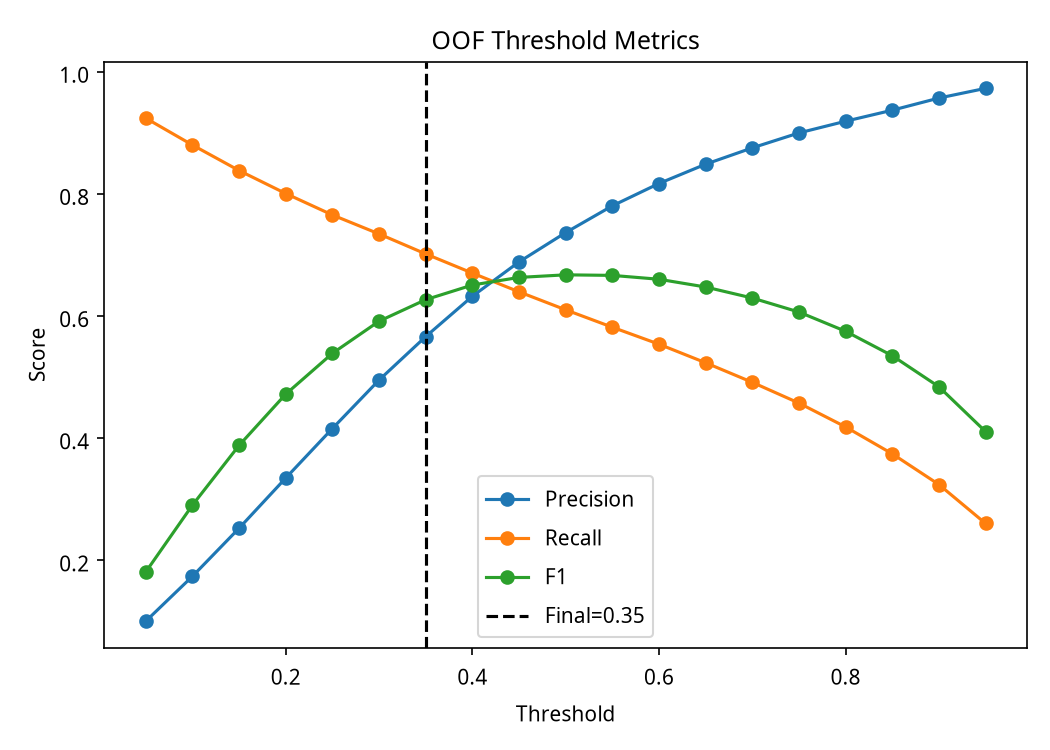

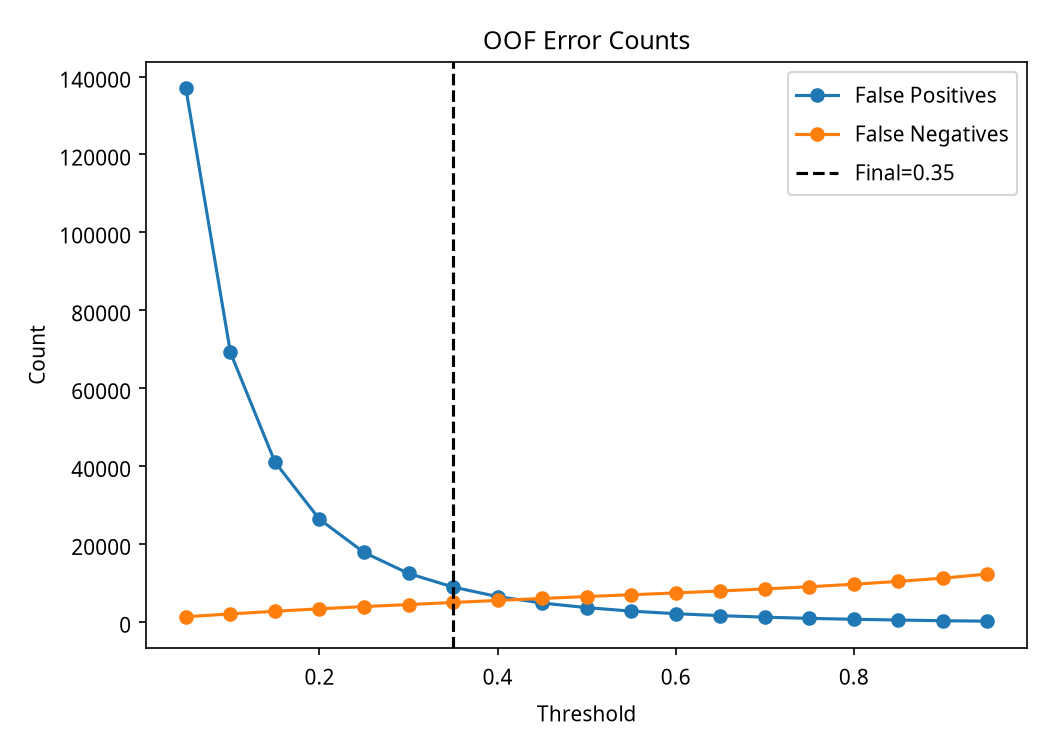

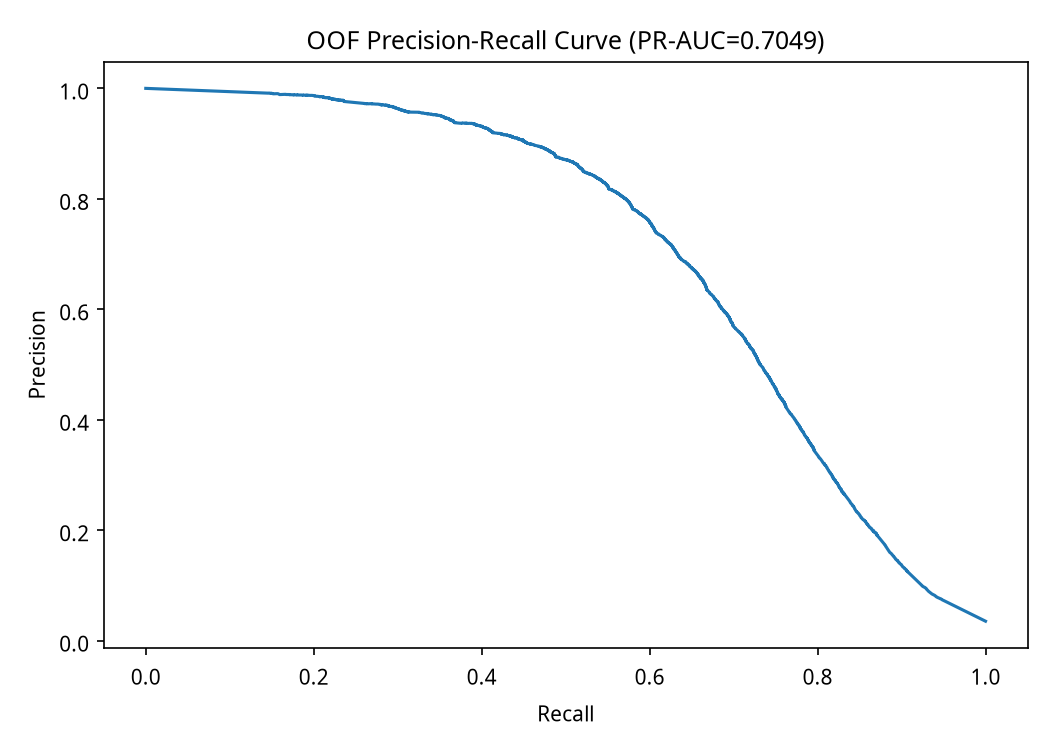

In [8]:
from IPython.display import display
# OOF plots and PR curve.
plt.figure(figsize=(7, 5))
plt.plot(analysis["threshold"], analysis["precision"], marker="o", label="Precision")
plt.plot(analysis["threshold"], analysis["recall"], marker="o", label="Recall")
plt.plot(analysis["threshold"], analysis["f1"], marker="o", label="F1")
plt.axvline(FINAL_THRESHOLD, color="black", linestyle="--", label=f"Final={FINAL_THRESHOLD:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.title("OOF Threshold Metrics"); plt.legend(); plt.tight_layout()
plt.savefig(PLOTS / "oof_threshold_metrics.png", dpi=150); display(plt.gcf()); plt.close()

plt.figure(figsize=(7, 5))
plt.plot(analysis["threshold"], analysis["false_positives"], marker="o", label="False Positives")
plt.plot(analysis["threshold"], analysis["false_negatives"], marker="o", label="False Negatives")
plt.axvline(FINAL_THRESHOLD, color="black", linestyle="--", label=f"Final={FINAL_THRESHOLD:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Count"); plt.title("OOF Error Counts"); plt.legend(); plt.tight_layout()
plt.savefig(PLOTS / "oof_error_counts.png", dpi=150); display(plt.gcf()); plt.close()

precision_curve, recall_curve, _ = precision_recall_curve(y_train, oof_proba)
plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"OOF Precision-Recall Curve (PR-AUC={average_precision_score(y_train, oof_proba):.4f})")
plt.tight_layout(); plt.savefig(PLOTS / "oof_precision_recall_curve.png", dpi=150); display(plt.gcf()); plt.close()


## 7. Save configuration and final report

In [7]:
# Test is first touched here, after FINAL_THRESHOLD was frozen.
test_proba = model.predict_proba(X_test)[:, 1]
final_test = metric_row(test_proba, y_test, FINAL_THRESHOLD)
test_baseline = metric_row(test_proba, y_test, 0.50)
print("Final test at frozen threshold:", final_test, flush=True)
print("Test baseline at 0.50:", test_baseline, flush=True)
def full_metrics(row, probabilities, labels, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "model": "Random Forest Tuned",
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision": row["precision"], "recall": row["recall"], "f1": row["f1"],
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "pr_auc": float(average_precision_score(labels, probabilities)),
        "tn": row["true_negatives"], "fp": row["false_positives"],
        "fn": row["false_negatives"], "tp": row["true_positives"],
    }

final_test_row = full_metrics(final_test, test_proba, y_test, FINAL_THRESHOLD)
baseline_test_row = full_metrics(test_baseline, test_proba, y_test, 0.50)
pd.DataFrame([final_test_row]).to_csv(RESULTS / "final_threshold_test_results.csv", index=False)
pd.DataFrame([baseline_test_row, final_test_row]).to_csv(RESULTS / "threshold_050_vs_final_test.csv", index=False)

nearby = np.round(np.unique(np.clip(FINAL_THRESHOLD + np.array([-0.10, -0.05, -0.02, 0, 0.02, 0.05, 0.10]), 0.01, 0.99)), 2)
pd.DataFrame([metric_row(test_proba, y_test, t) for t in nearby]).to_csv(RESULTS / "threshold_sensitivity_test.csv", index=False)
threshold_config = {
    "classification_threshold": FINAL_THRESHOLD,
    "risk_levels": {
        "low": "probability < 0.30",
        "medium": "0.30 <= probability < 0.70",
        "high": "probability >= 0.70",
    },
    "selection_metric": "OOF simulated cost with COST_FP=1 and COST_FN=5; F1 used as tie-break",
    "cost_fp": 1,
    "cost_fn": 5,
    "threshold_selected_without_test_data": True,
}
with open(MODELS / "threshold_config.json", "w") as handle:
    json.dump(threshold_config, handle, indent=2)

report = f'''# Phase 9 — Threshold Optimization Report

## Model

The model is the Phase 8 tuned Random Forest loaded from `models/best_tuned_model.pkl`. Threshold selection used 5-fold out-of-fold probabilities from `X_train` and `y_train` only. The test set was used only after the threshold was frozen.

## OOF threshold selection

The OOF baseline at threshold 0.50 was: **Precision={baseline['precision']:.6f}, Recall={baseline['recall']:.6f}, F1={baseline['f1']:.6f}, FP={baseline['false_positives']}, FN={baseline['false_negatives']}**.

The best F1 candidate was threshold **{best_f1['threshold']:.2f}** with Precision={best_f1['precision']:.6f}, Recall={best_f1['recall']:.6f}, and F1={best_f1['f1']:.6f}.

The lowest simulated-cost candidate, under the initial scenario COST_FP=1 and COST_FN=5, was threshold **{best_cost['threshold']:.2f}** with Precision={best_cost['precision']:.6f}, Recall={best_cost['recall']:.6f}, F1={best_cost['f1']:.6f}, FP={int(best_cost['false_positives'])}, FN={int(best_cost['false_negatives'])}, and simulated cost={int(best_cost['simulated_cost'])}. These costs are illustrative and are not claimed to be real business costs.

## Final selected threshold

`FINAL_THRESHOLD = {FINAL_THRESHOLD:.2f}`

The threshold was selected from OOF training predictions using the simulated cost rule, with F1 as a tie-break. It was frozen before test probabilities were generated. The expected benefit is fewer false negatives under the assumed higher FN cost. The trade-off is potentially more false positives and operational workload.

## Final test performance

| Metric | Threshold 0.50 | Final threshold |
|---|---:|---:|
| Accuracy | {baseline_test_row['accuracy']:.6f} | {final_test_row['accuracy']:.6f} |
| Balanced Accuracy | {baseline_test_row['balanced_accuracy']:.6f} | {final_test_row['balanced_accuracy']:.6f} |
| Precision | {baseline_test_row['precision']:.6f} | {final_test_row['precision']:.6f} |
| Recall | {baseline_test_row['recall']:.6f} | {final_test_row['recall']:.6f} |
| F1 | {baseline_test_row['f1']:.6f} | {final_test_row['f1']:.6f} |
| ROC-AUC | {baseline_test_row['roc_auc']:.6f} | {final_test_row['roc_auc']:.6f} |
| PR-AUC | {baseline_test_row['pr_auc']:.6f} | {final_test_row['pr_auc']:.6f} |
| FP | {baseline_test_row['fp']} | {final_test_row['fp']} |
| FN | {baseline_test_row['fn']} | {final_test_row['fn']} |
| TP | {baseline_test_row['tp']} | {final_test_row['tp']} |
| TN | {baseline_test_row['tn']} | {final_test_row['tn']} |

PR-AUC is threshold-independent, whereas F1, precision, recall, and confusion-matrix counts depend on the selected threshold.

## Risk levels

Low risk is probability < 0.30, medium risk is 0.30 to below 0.70, and high risk is probability >= 0.70. These are presentation boundaries, not the classification threshold. The prediction flow is: fraud probability → risk level → compare probability with the frozen classification threshold → Fraud or Legitimate.

## Decision

**THRESHOLD SUCCESSFULLY SELECTED.** The threshold is frozen at {FINAL_THRESHOLD:.2f}. Phase 10 must not begin until explicit confirmation.
'''
(RESULTS / "phase9_final_report.md").write_text(report, encoding="utf-8")
print("Saved Phase 9 results and plots to:", RESULTS, flush=True)
print("PHASE 9 COMPLETE — STOP FOR CONFIRMATION", flush=True)


Final test at frozen threshold: {'threshold': 0.35, 'precision': 0.5821185617103984, 'recall': 0.7246552141301718, 'f1': 0.6456132787238629, 'false_positives': 2150, 'false_negatives': 1138, 'true_positives': 2995, 'true_negatives': 111825, 'simulated_cost': 7840}


Test baseline at 0.50: {'threshold': 0.5, 'precision': 0.7575583069392456, 'recall': 0.6365835954512461, 'f1': 0.6918222455955825, 'false_positives': 842, 'false_negatives': 1502, 'true_positives': 2631, 'true_negatives': 113133, 'simulated_cost': 8352}


Saved Phase 9 results and plots to: /home/ubuntu/fraud_local/results


PHASE 9 COMPLETE — STOP FOR CONFIRMATION


## Phase 9 conclusion

The final threshold is frozen only after OOF analysis. Review the saved report before proceeding.